In [66]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [67]:
BATCH_SIZE = 64
BLOCK_SIZE = 256
max_iters = 5000
lr = 3e-4

n_embed = 256
n_head = 4
n_layer = 6
dropout=0.2
head_size = 64

In [68]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [69]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-19 09:17:25--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt.3’

input.txt.3         100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-19 09:17:25 (35.9 MB/s) - ‘input.txt.3’ saved [1115394/1115394]



In [70]:
with open('input.txt', 'r', encoding='utf-8') as file:
    text = file.read()

In [71]:
print('length of the text:', len(text))

length of the text: 1115394


In [72]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [73]:
chars = sorted(set(text))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [74]:
word2idx = {el:i for i, el in enumerate(chars)}
idx2word = {i:el for i, el in enumerate(chars)}

In [75]:
encode = lambda s: [word2idx[c] for c in s]
decode = lambda s: ''.join([idx2word[c] for c in s])

In [76]:
print(encode('hello world'))

[46, 43, 50, 50, 53, 1, 61, 53, 56, 50, 42]


ChatGPT использует токенизатор tiktoken

In [77]:
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.type)
print(data[:1000])

torch.Size([1115394]) <built-in method type of Tensor object at 0x7b5c9d154050>
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 

In [78]:
# У нас есть датасет, делим его на test_size=0.1
n = int(len(data) * 0.9)
train_data = data[:n]
valid_data = data[n:]

In [79]:
# Теперь нам нужно разбить на батчи
# block_size = 8
print(train_data[:block_size+1])

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])


In [80]:
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for i in range(block_size):
    context = x[:i + 1]
    target = y[i]
    print(f'input: {context} output: {target}')

input: tensor([18]) output: 47
input: tensor([18, 47]) output: 56
input: tensor([18, 47, 56]) output: 57
input: tensor([18, 47, 56, 57]) output: 58
input: tensor([18, 47, 56, 57, 58]) output: 1
input: tensor([18, 47, 56, 57, 58,  1]) output: 15
input: tensor([18, 47, 56, 57, 58,  1, 15]) output: 47
input: tensor([18, 47, 56, 57, 58,  1, 15, 47]) output: 58


In [81]:
def get_batch(split):
    data = train_data if split == 'train' else valid_data
    idx = torch.randint(len(data) - BLOCK_SIZE, (BATCH_SIZE,)) # генерируем 4 случайных числа для нахождения начала предложения
    # вычитаем block_size, чтобы допустим [1,2,3,4,5,6,7,8,9,10] при i=2 можно было взять [2:9] числа и предсказать число 9
    x = torch.stack([data[i:i+BLOCK_SIZE] for i in idx])
    y = torch.stack([data[i+1:i+BLOCK_SIZE+1] for i in idx])
    return x, y

xb, yb = get_batch('train')

# for b in range(BATCH_SIZE):
#     for t in range(BLOCK_SIZE):
#         context = xb[b, :t+1]
#         target = yb[b, t]
#         print(f'input: {context} output: {target}')

In [82]:
# реализация головы или же self-attention
class Head(nn.Module):
    def __init__(self, head_size):
        super(Head, self).__init__()
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)))
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)
        d_k = q.size(-1)

        scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(d_k)
        mask = self.tril[:T, :T]

        scores = scores.masked_fill(mask == 0, float('-inf'))
        p_attn = F.softmax(scores, dim=-1)
        p_attn = self.dropout(p_attn)

        out = torch.matmul(p_attn, v)
        return out

In [83]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super(MultiHeadAttention, self).__init__()
        self.heads = nn.ModuleList([Head(head_size) for i in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embed)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

In [84]:
class FeedForward(nn.Module):
    def __init__(self, n_embed):
        super(FeedForward, self).__init__()
        self.w1 = nn.Linear(n_embed, 4 * n_embed)
        self.w2 = nn.Linear(4 * n_embed, n_embed)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        out = self.w2(self.dropout(self.w1(x).relu()))
        return out

In [85]:
class GPTBlock(nn.Module):
    def __init__(self, n_embed, n_head):
        super(GPTBlock, self).__init__()
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffn = FeedForward(n_embed)
        self.ln1 = nn.LayerNorm(n_embed)
        self.ln2 = nn.LayerNorm(n_embed)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

In [86]:
class GPT2(nn.Module):
    def __init__(self):
        super(GPT2, self).__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embed)
        self.positional_embedding = nn.Embedding(BLOCK_SIZE, n_embed)
        self.blocks = nn.Sequential(*[GPTBlock(n_embed, n_head) for i in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embed)
        self.lm_head = nn.Linear(n_embed, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.positional_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def _init_weights(self, module): # будем изанчально задавать веса модели из гауссовского распределения
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def generate(self, idx, max_new_tokens): #авторегрессивно генерируем токены
        for i in range(max_new_tokens):
            idx_text = idx[:, -BLOCK_SIZE:] # берем крайние block_size токенов
            logits, loss = self(idx_text)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, idx_next], dim=-1)
        return idx

In [87]:
model = GPT2().to(device)
print(sum(param.numel() for param in model.parameters())/1e6, 'M parameters')

4.833345 M parameters


In [88]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)


In [91]:
max_iters = 5000
step = 0

for iter in tqdm(range(max_iters)):
    xb, yb = get_batch('train')
    xb = xb.to(device)
    yb = yb.to(device)

    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if iter % 500 == 0:
        step += 1
        print(f'iter {step} loss {loss.item():.4f}')

context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=500)[0].tolist()))

  0%|          | 0/5000 [00:00<?, ?it/s]

iter 1 loss 2.8247
iter 2 loss 2.1343
iter 3 loss 1.7991
iter 4 loss 1.5822
iter 5 loss 1.5445
iter 6 loss 1.4597
iter 7 loss 1.4235
iter 8 loss 1.3853
iter 9 loss 1.3781
iter 10 loss 1.3597

BUCKINGHAM:
When thee not of your fier men meaning prince;
But will to see again.

KING EDWARDomas will, Buckisluman, and meet trumpeth.
Deather, 'twas to old damnable langure?

ISABELLA:
What longer or the death? visit once,
And plotted the weepert trouble's that,
And I show four applity,
In that done yield my brother.

GLOUCESTER:
Susporth to the new wolve: here then Mercusance,
The cut geall Our gree depose is his wilf:
And in my imenders,
Hath a modement this too old speed in Volscianius wil


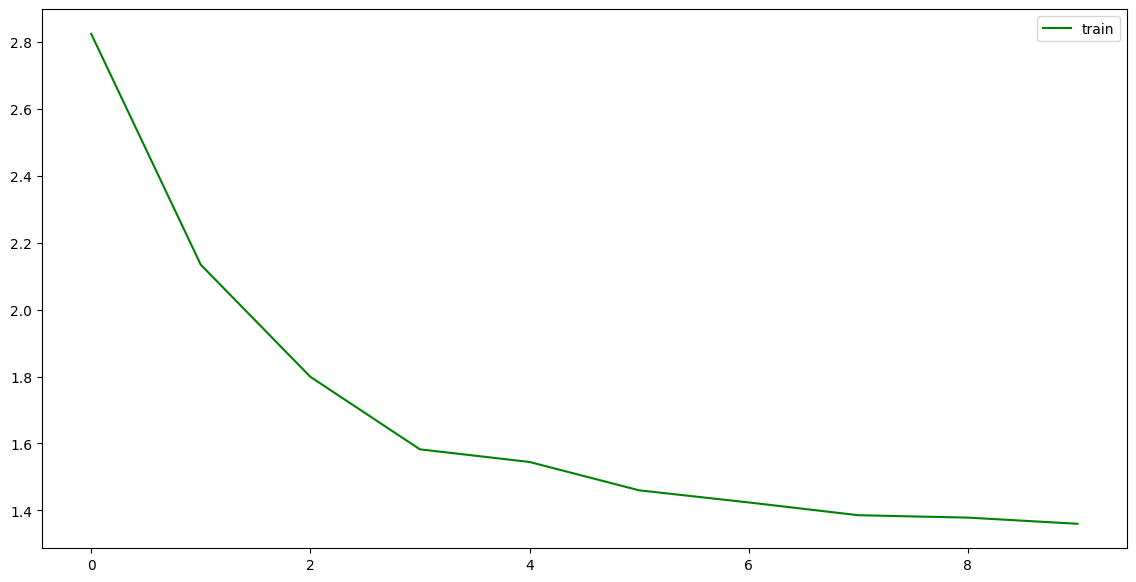

In [96]:
losses = [2.8247, 2.1343, 1.7991, 1.5822, 1.5445,
          1.4597, 1.4235, 1.3853, 1.3781, 1.3597]

fig = plt.figure(figsize=(14,7))
ax = plt.subplot(111)
plt.plot(losses, label='train', c='green')

plt.legend()
plt.show()